# Problemas de valores en la frontera: diferencias finitas

En este notebook se desarrollan las implementaciones iniciales de la clase:

1. Discretización de un BVP.
2. Construcción del sistema tridiagonal mediante diferencias finitas.
3. Ejemplo resuelto con solución exacta.
4. Visualización y cálculo del error.
5. Estudio de convergencia.
6. Aplicación física: conducción de calor en una barra con generación uniforme.
7. Comparación con la solución exacta.


## 1. Idea matemática

Consideramos

$$
u''(x)=f(x),\qquad a\le x\le b,
$$

con condiciones de Dirichlet

$$
u(a)=\alpha,\qquad u(b)=\beta.
$$

Con una malla uniforme,

$$
h=\frac{b-a}{N},\qquad x_i=a+ih,
$$

y usando la diferencia centrada,

$$
u''(x_i)\approx
\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}.
$$

Por tanto,

$$
u_{i-1}-2u_i+u_{i+1}=h^2f(x_i).
$$

Los valores interiores forman un sistema lineal

$$
A\mathbf{u}=\mathbf{b}.
$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)


## 2. Función general para construir el BVP

La siguiente función construye la malla, la matriz tridiagonal y el vector del lado derecho para

$$
u''(x)=f(x),
$$

con $u(a)=\alpha$ y $u(b)=\beta$.


In [2]:
def construir_bvp_diferencias_finitas(a, b, N, f, alpha, beta):
    h = (b - a) / N
    x = np.linspace(a, b, N + 1)

    # Puntos interiores
    xi = x[1:-1]

    # Matriz del sistema
    A = np.zeros((N - 1, N - 1))

    for i in range(N - 1):
        A[i, i] = -2.0

        if i > 0:
            A[i, i - 1] = 1.0

        if i < N - 2:
            A[i, i + 1] = 1.0

    # Vector derecho
    rhs = h**2 * f(xi)

    # Incorporación de las condiciones de frontera
    rhs[0] -= alpha
    rhs[-1] -= beta

    return x, A, rhs


### Observación sobre las condiciones de frontera

Para el primer punto interior:

$$
u_0-2u_1+u_2=h^2f(x_1).
$$

Como $u_0=\alpha$:

$$
-2u_1+u_2=h^2f(x_1)-\alpha.
$$

De manera análoga, la última ecuación incorpora $\beta$.

Por eso las condiciones de frontera aparecen modificando el vector derecho.


## 3. Función para resolver y reconstruir la solución completa

In [3]:
def resolver_bvp(a, b, N, f, alpha, beta):
    x, A, rhs = construir_bvp_diferencias_finitas(
        a, b, N, f, alpha, beta
    )

    u_interior = np.linalg.solve(A, rhs)

    u = np.zeros(N + 1)
    u[0] = alpha
    u[-1] = beta
    u[1:-1] = u_interior

    return x, u, A, rhs


## 4. Ejemplo resuelto 1

Resolver

$$
u''(x)=-\pi^2\sin(\pi x),
$$

para $0\le x\le1$, con

$$
u(0)=0,\qquad u(1)=0.
$$

La solución exacta es

$$
u(x)=\sin(\pi x).
$$


In [4]:
def f_ejemplo1(x):
    return -np.pi**2 * np.sin(np.pi * x)

a = 0.0
b = 1.0
N = 20
alpha = 0.0
beta = 0.0

x, u, A, rhs = resolver_bvp(
    a, b, N, f_ejemplo1, alpha, beta
)

u_exacta = np.sin(np.pi * x)

print("Número de incógnitas interiores:", N - 1)
print("Tamaño de la matriz:", A.shape)
print("Error máximo:", np.max(np.abs(u - u_exacta)))


Número de incógnitas interiores: 19
Tamaño de la matriz: (19, 19)
Error máximo: 0.002058706764533902


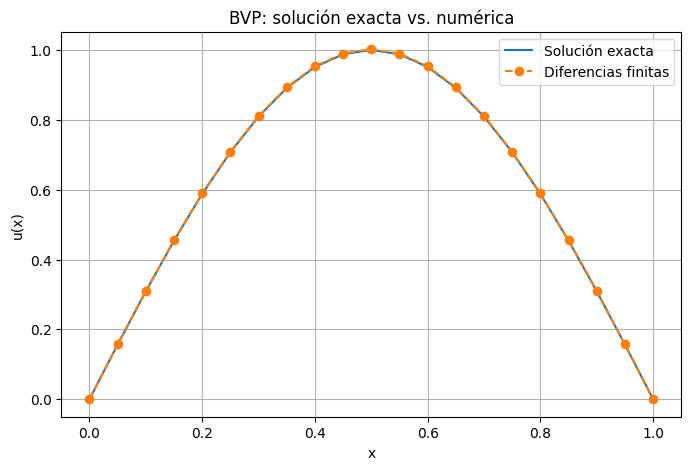

In [5]:
plt.plot(x, u_exacta, label="Solución exacta")
plt.plot(x, u, "o--", label="Diferencias finitas")

plt.xlabel("x")
plt.ylabel("u(x)")
plt.title("BVP: solución exacta vs. numérica")
plt.grid()
plt.legend()
plt.show()


## 5. Inspección de la matriz

Para un número pequeño de nodos es útil visualizar explícitamente la estructura del sistema.


In [6]:
N_pequeno = 6

x6, u6, A6, rhs6 = resolver_bvp(
    0, 1, N_pequeno, f_ejemplo1, 0, 0
)

print("Matriz A:")
print(A6)

print("\nVector derecho:")
print(rhs6)


Matriz A:
[[-2.  1.  0.  0.  0.]
 [ 1. -2.  1.  0.  0.]
 [ 0.  1. -2.  1.  0.]
 [ 0.  0.  1. -2.  1.]
 [ 0.  0.  0.  1. -2.]]

Vector derecho:
[-0.13707784 -0.23742578 -0.27415568 -0.23742578 -0.13707784]


## 6. Error máximo

Definimos el error absoluto nodo a nodo como

$$
e_i=|u_i-u(x_i)|.
$$

El error máximo o norma infinito discreta es

$$
E_\infty=\max_i e_i.
$$


In [7]:
error = np.abs(u - u_exacta)

print("Error máximo =", np.max(error))
print("Error promedio =", np.mean(error))


Error máximo = 0.002058706764533902
Error promedio = 0.001245635697234053


## 7. Estudio de convergencia

Para el esquema centrado de la segunda derivada esperamos

$$
E(h)\approx Ch^2.
$$

Calcularemos el error para varias mallas.


In [8]:
Ns = [10, 20, 40, 80, 160]

hs = []
errores = []

for N in Ns:
    x, u, _, _ = resolver_bvp(
        0, 1, N, f_ejemplo1, 0, 0
    )

    exacta = np.sin(np.pi * x)
    h = 1 / N
    error = np.max(np.abs(u - exacta))

    hs.append(h)
    errores.append(error)

for N, h, error in zip(Ns, hs, errores):
    print(f"N={N:3d}, h={h:.6f}, error={error:.6e}")


N= 10, h=0.100000, error=8.265417e-03
N= 20, h=0.050000, error=2.058707e-03
N= 40, h=0.025000, error=5.142005e-04
N= 80, h=0.012500, error=1.285204e-04
N=160, h=0.006250, error=3.212824e-05


In [9]:
ordenes = []

for i in range(len(errores) - 1):
    p = np.log(errores[i] / errores[i + 1]) / np.log(hs[i] / hs[i + 1])
    ordenes.append(p)

for i, p in enumerate(ordenes):
    print(f"Entre N={Ns[i]} y N={Ns[i+1]}: orden observado = {p:.4f}")


Entre N=10 y N=20: orden observado = 2.0053
Entre N=20 y N=40: orden observado = 2.0013
Entre N=40 y N=80: orden observado = 2.0003
Entre N=80 y N=160: orden observado = 2.0001


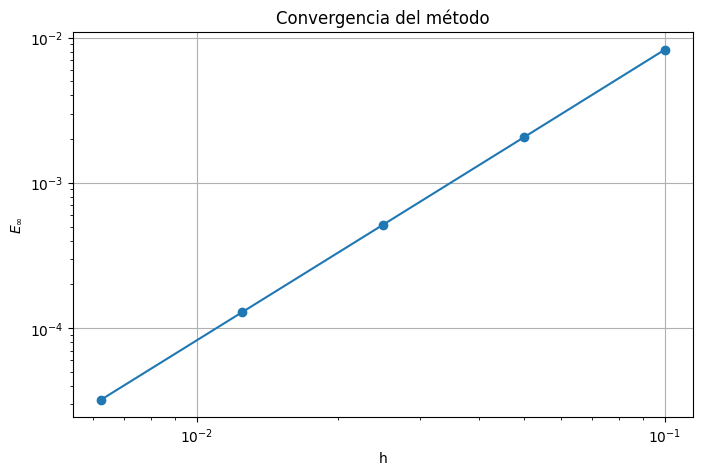

In [10]:
plt.loglog(hs, errores, "o-")
plt.xlabel("h")
plt.ylabel(r"$E_\infty$")
plt.title("Convergencia del método")
plt.grid()
plt.show()


## 8. Ejemplo resuelto 2: barra con generación de calor

Consideramos el modelo

$$
T''(x)=-10,
$$

con

$$
T(0)=100,\qquad T(1)=50.
$$

La solución exacta es

$$
T(x)=100-45x-5x^2.
$$

Este problema representa una barra unidimensional con generación uniforme de calor en un modelo estacionario simplificado.


In [11]:
def f_barra(x):
    return -10.0 * np.ones_like(x, dtype=float)

def T_exacta(x):
    return 100.0 - 45.0*x - 5.0*x**2

N = 20

xT, T, AT, rhsT = resolver_bvp(
    0, 1, N, f_barra, 100.0, 50.0
)

T_ex = T_exacta(xT)

print("Error máximo:", np.max(np.abs(T - T_ex)))


Error máximo: 1.4210854715202004e-14


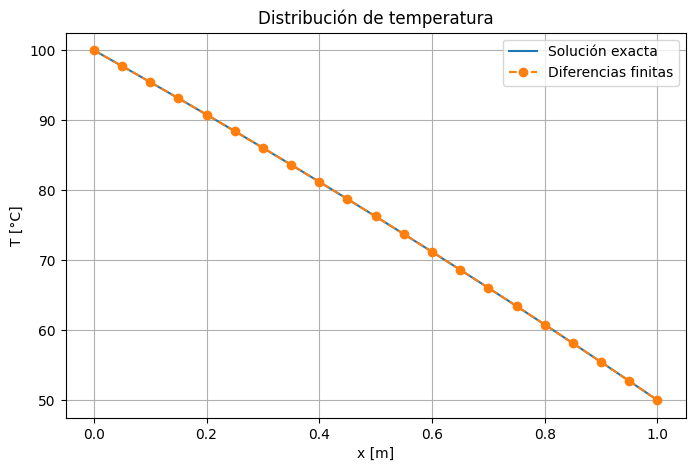

In [12]:
plt.plot(xT, T_ex, label="Solución exacta")
plt.plot(xT, T, "o--", label="Diferencias finitas")

plt.xlabel("x [m]")
plt.ylabel("T [°C]")
plt.title("Distribución de temperatura")
plt.grid()
plt.legend()
plt.show()


## 9. Comparación de precisión para el problema físico

In [13]:
Ns = [5, 10, 20, 40, 80]

errores_T = []

for N in Ns:
    xT, T, _, _ = resolver_bvp(
        0, 1, N, f_barra, 100.0, 50.0
    )

    error = np.max(np.abs(T - T_exacta(xT)))
    errores_T.append(error)

for N, error in zip(Ns, errores_T):
    print(f"N={N:3d}, error máximo={error:.6e}")


N=  5, error máximo=1.421085e-14
N= 10, error máximo=1.421085e-14
N= 20, error máximo=1.421085e-14
N= 40, error máximo=4.121148e-13
N= 80, error máximo=8.952838e-13


## 10. Ejercicio guiado adicional: inspección de la solución

Antes de resolver el ejercicio de tarea, es útil comprobar las condiciones de frontera y observar el perfil.


In [14]:
print("Temperatura en x=0:", T[0])
print("Temperatura en x=1:", T[-1])
print("Temperatura mínima:", np.min(T))
print("Temperatura máxima:", np.max(T))


Temperatura en x=0: 100.0
Temperatura en x=1: 50.0
Temperatura mínima: 50.0
Temperatura máxima: 100.0


## 11. Plantilla para un nuevo BVP

La siguiente plantilla puede reutilizarse para otros problemas de la misma forma:

1. definir $f(x)$;
2. especificar $a$, $b$, $N$, $\alpha$ y $\beta$;
3. llamar a `resolver_bvp`;
4. comparar con una solución exacta si está disponible;
5. estudiar el error y la convergencia.


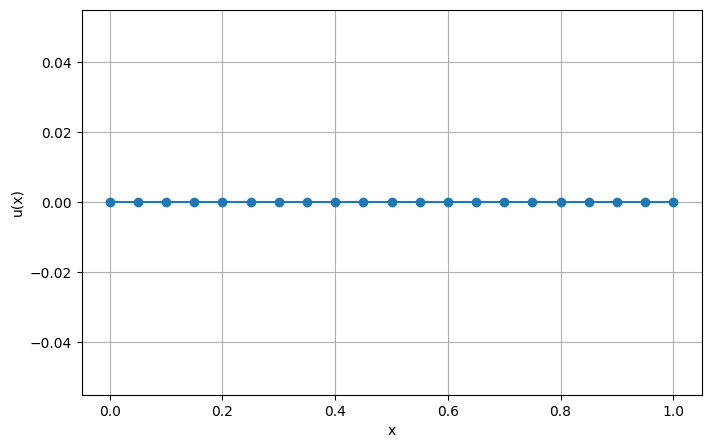

In [15]:
# Ejemplo de plantilla

def f_nuevo(x):
    # Definir aquí el lado derecho de la EDO
    return np.zeros_like(x)

a = 0.0
b = 1.0
N = 20
alpha = 0.0
beta = 0.0

x, u, A, rhs = resolver_bvp(
    a, b, N, f_nuevo, alpha, beta
)

plt.plot(x, u, "o-")
plt.xlabel("x")
plt.ylabel("u(x)")
plt.grid()
plt.show()


# Ejercicios para realizar en casa

## Ejercicio 1: convergencia

Resolver

$$
u''(x)=-4\pi^2\sin(2\pi x),
$$

con

$$
u(0)=u(1)=0,
$$

cuya solución exacta es

$$
u(x)=\sin(2\pi x).
$$

Usar $N=10,20,40,80$, calcular el error máximo y estimar el orden de convergencia.

## Ejercicio 2: aplicación física

Resolver

$$
T''(x)=-10,
$$

con

$$
T(0)=100^\circ C,\qquad T(1)=50^\circ C.
$$

Comparar con

$$
T(x)=100-45x-5x^2.
$$

Construir la matriz, resolver el sistema, graficar la solución y calcular el error máximo.

